# Group 3 - Notebook 1: Source Data → Analytical Base Table (ABT)
## Appliances Energy Prediction

**Dataset:** UCI Appliances Energy Prediction (`energydata_complete.csv`), 2016-01-11 to 2016-05-27, 10-minute intervals, 19,735 records, 29 raw columns.

**Business question:** How can a smart home energy management platform optimize indoor environmental conditions and time-of-use schedules to reduce household appliance energy consumption without compromising occupant comfort?

**Analytical questions (answered in Notebook 2):**
1. What is the typical/observed range of temperature and humidity in key rooms, and how does appliance energy use change as values move away from their typical range?
2. At what specific T/RH thresholds (per room) does Appliances energy begin to increase significantly, and which rooms cross these thresholds most frequently?
3. How does the proportion of variance in appliance energy explained by *temporal* features compare to that explained by *environmental* variables?

**Purpose:** take the raw file to a validated ABT (load, nulls, cleaning and flags, target transforms, calendar and diagnostic features, feature groups, descriptive statistics). No modeling happens here.
**Outputs** (`abt_outputs/`): `abt_appliances_energy.csv`, `feature_groups.json`, `abt_metadata.json`, `cleaning_log.csv`.
**Designed for "Restart & Run All".** The success message in Section 5 prints only if every check passes. The ABT is a preparation artifact, not a train/test split.

## 0 · Setup & Runtime Timer

Paths and thresholds live in the configuration cell. Per the dataset documentation, `RH_5` is the bathroom humidity sensor and `RH_6` is outdoor; units are not stated, so none are assumed on plots.

In [1]:
import json, time
from datetime import datetime
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
try:
    from IPython.display import display, Markdown
except ImportError:
    display, Markdown = print, str

T0 = time.perf_counter()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}"); pd.set_option("display.width", 200)

In [2]:
# ---------------- configuration ----------------
CANDIDATES = ["energydata_complete.csv", "data/energydata_complete.csv",
              "/mnt/data/energydata_complete.csv", "/mnt/user-data/uploads/energydata_complete.csv"]
OUT = Path("abt_outputs")
SEED = 42
TARGET = "Appliances"
STEP = pd.Timedelta(minutes=10)
RH6_LOW = 10.0            # flag RH_6 below this
TUKEY_K = 1.5             # bathroom spike fence: Q3 + k*IQR on RH_5
CAP_Q = 0.99              # P99 flag and cap for the target
INTERP_LIMIT = 6          # max records filled by time interpolation (1 hour)
N_RANDOM = 20
# -----------------------------------------------

OUT.mkdir(exist_ok=True)
LOG, CHECKS = [], {}
def log(step, action, detail=""): LOG.append({"step": step, "action": action, "detail": detail})
def check(name, ok, msg=""):
    CHECKS[name] = bool(ok)
    if not ok: raise AssertionError(f"CHECK FAILED - {name}. {msg}")

## 1 · Load, Inspect & Nulls

Load the 10-minute log, then check its structure and missing values. To use another file, place it in the working directory or `data/`, or edit `CANDIDATES`.

### Method: Tabular Data Ingestion with pandas

- **Reference:** McKinney, W. (2010). Data structures for statistical computing in Python. In S. van der Walt & J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 56–61). https://doi.org/10.25080/Majora-92bf1922-00a
- **Documentation:** https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html
- **Purpose in this project:** loads the log, checks that `date` and `Appliances` exist, and parses `date` as a datetime for every later time-based step.

In [3]:
path = next((Path(p) for p in CANDIDATES if Path(p).is_file()), None)
if path is None:
    raise FileNotFoundError("energydata_complete.csv not found. Put it in the working directory, 'data/', or '/mnt/data', or edit CANDIDATES in Section 0.")
df = pd.read_csv(path)
df.columns = df.columns.str.strip()
check("required columns", {"date", TARGET} <= set(df.columns), f"need 'date' and '{TARGET}'; found {list(df.columns)}")
df["date"] = pd.to_datetime(df["date"])

### Method: Structural Data-Quality Checks (Order, Duplicates, Timestamp Cadence)

- **Reference:** Zhou, Y., Tu, F., Sha, K., Ding, J., & Chen, H. (2024). A survey on data quality dimensions and tools for machine learning. *arXiv*:2406.19614 (accepted at IEEE AITest 2024). https://doi.org/10.48550/arXiv.2406.19614
- **Documentation:** https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html
- **Purpose in this project:** sorts chronologically and reports shape, dtypes, date range, duplicates and whether records are exactly 10 minutes apart. Gaps are reported, never filled.

In [4]:
sorted_in = df["date"].is_monotonic_increasing
df = df.sort_values("date", kind="mergesort").reset_index(drop=True)
N_READ = len(df)

gaps = df["date"].diff().dropna()
n_exact, n_gap = int((gaps == STEP).sum()), int((gaps > STEP).sum())
print(f"File: {path}\nShape: {df.shape[0]:,} rows x {df.shape[1]} columns | dtypes: {df.dtypes.astype(str).value_counts().to_dict()}")
print(f"Date range: {df.date.min()} -> {df.date.max()} | already sorted: {sorted_in}")
print(f"Duplicate rows: {int(df.duplicated().sum())} | duplicate timestamps: {int(df.date.duplicated().sum())}")
print(f"Cadence: {n_exact:,} of {len(gaps):,} intervals are exactly 10 min | gaps: {n_gap} | other: {len(gaps) - n_exact - n_gap}")
if n_exact != len(gaps): print("WARNING: irregular cadence; gaps are kept as-is, not filled."); log("1", "warning", "irregular cadence")

File: energydata_complete.csv
Shape: 19,735 rows x 29 columns | dtypes: {'float64': 26, 'int64': 2, 'datetime64[us]': 1}
Date range: 2016-01-11 17:00:00 -> 2016-05-27 18:00:00 | already sorted: True
Duplicate rows: 0 | duplicate timestamps: 0
Cadence: 19,734 of 19,734 intervals are exactly 10 min | gaps: 0 | other: 0


**Interpretation:** The printout confirms size, date coverage, duplicate count and cadence, so any structural problem is visible before cleaning begins.

### Method: Schema & Missing-Value (Null-%) Audit

- **Reference:** Zhou, Y., Tu, F., Sha, K., Ding, J., & Chen, H. (2024). A survey on data quality dimensions and tools for machine learning. *arXiv*:2406.19614 (accepted at IEEE AITest 2024). https://doi.org/10.48550/arXiv.2406.19614
- **Documentation:** https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html
- **Purpose in this project:** converts hidden missing values (text markers, ±infinity) to NaN with a count, then reports missing count and percentage per column.

In [5]:
# hidden missing: text columns that should be numeric, and infinite values
n_converted = 0
for c in df.columns.drop("date"):
    if df[c].dtype == object:
        conv = pd.to_numeric(df[c].str.strip(), errors="coerce")
        n_converted += int(conv.isna().sum() - df[c].isna().sum())
        df[c] = conv
inf_mask = np.isinf(df.drop(columns="date").to_numpy(dtype=float))
df = df.replace([np.inf, -np.inf], np.nan)
print(f"Hidden-missing scan: {n_converted} text values and {int(inf_mask.sum())} infinite values converted to NaN.")
log("1", "hidden-missing scan", f"text->NaN: {n_converted}; inf->NaN: {int(inf_mask.sum())}")

nulls = pd.DataFrame({"missing": df.isna().sum(), "missing_pct": df.isna().mean() * 100}).sort_values("missing", ascending=False)
RAW_MISSING_PCT = nulls["missing_pct"]
print(f"Total missing cells: {int(nulls.missing.sum()):,} ({nulls.missing.sum() / df.size * 100:.3f}%)")
display(nulls.head(8))

Hidden-missing scan: 0 text values and 0 infinite values converted to NaN.
Total missing cells: 0 (0.000%)


,missing,missing_pct
date,0,0.000
Appliances,0,0.000
lights,0,0.000
T1,0,0.000
RH_1,0,0.000
T2,0,0.000
RH_2,0,0.000
T3,0,0.000


**Interpretation:** The null table lists the most-affected columns first; a table of zeros means no column has missing values.

## 2 · Clean & Prepare

Drop non-signal columns, flag anomalies **without deleting rows**, and add capped and log-transformed targets. `Appliances` itself is never modified.

### Method: Redundancy Test and Removal of Non-Signal Columns

- **Reference:** Candanedo, L. M., Feldheim, V., & Deramaix, D. (2017). Data driven prediction models of energy use of appliances in a low-energy house. *Energy and Buildings, 140*, 81–97. https://doi.org/10.1016/j.enbuild.2017.01.083
- **Documentation:** https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop.html
- **Purpose in this project:** `rv2` is dropped only if identical to `rv1`, which stays as the negative control. `lights` is dropped as another metered load, not an environmental feature.

In [6]:
# --- drops ---
same = df["rv1"].isna().equals(df["rv2"].isna()) and np.allclose(df["rv1"].dropna(), df["rv2"].dropna(), rtol=1e-9, atol=1e-12)
check("rv1 == rv2", same, "rv2 is not a duplicate of rv1; do not drop it without review.")
df = df.drop(columns=["rv2", "lights"])
log("2", "drop rv2, lights", "rv2 identical to rv1 (rv1 kept); lights is another metered load")
ORIGINAL_COLS = list(df.columns)

### Method: Tukey-Fence and Rule-Based Anomaly Flags

- **Reference:** Tukey, J. W. (1977). *Exploratory data analysis*. Addison-Wesley.
- **Documentation:** https://pandas.pydata.org/docs/reference/api/pandas.Series.quantile.html
- **Purpose in this project:** flags `RH_6 < 10`, `RH_5` above Q3 + 1.5 × IQR, and `Appliances` above P99. The fence is global, so it flags high values rather than sudden jumps. Rows are kept.

In [7]:
# --- flags (rows are kept) ---
q1, q3 = df["RH_5"].quantile([0.25, 0.75])
FENCE = float(q3 + TUKEY_K * (q3 - q1))
P99 = float(df[TARGET].quantile(CAP_Q))

df["flag_rh6_below_10"] = df["RH_6"] < RH6_LOW
df["flag_bathroom_spike"] = df["RH_5"] > FENCE
df["flag_appliances_above_p99"] = df[TARGET] > P99
FLAGS = ["flag_rh6_below_10", "flag_bathroom_spike", "flag_appliances_above_p99"]
log("2", "flags", f"RH_6<{RH6_LOW}; RH_5>{FENCE:.3f} (Q3+{TUKEY_K}*IQR); {TARGET}>{P99:.1f} (P{int(CAP_Q*100)})")

### Method: Percentile Capping (Winsorizing) and log1p Transform

- **Reference:** Tukey, J. W. (1962). The future of data analysis. *The Annals of Mathematical Statistics, 33*(1), 1–67. https://doi.org/10.1214/aoms/1177704711; Box, G. E. P., & Cox, D. R. (1964). An analysis of transformations. *Journal of the Royal Statistical Society: Series B, 26*(2), 211–252. https://doi.org/10.1111/j.2517-6161.1964.tb00553.x
- **Documentation:** https://pandas.pydata.org/docs/reference/api/pandas.Series.clip.html and https://numpy.org/doc/stable/reference/generated/numpy.log1p.html
- **Purpose in this project:** a P99-capped copy supports sensitivity runs, and `log1p` (a shifted log from the Box–Cox family) reduces right skew; it is defined at 0 and needs non-negative values. The original target is untouched.

In [8]:
# --- target derivatives (original kept) ---
check("target non-negative", (df[TARGET].dropna() >= 0).all(), "log1p needs non-negative values.")
CAP, LOG1P, LOG1P_CAP = f"{TARGET}_p99cap", f"log1p_{TARGET}", f"log1p_{TARGET}_p99cap"
TARGET_ORIG = df[TARGET].copy()
df[CAP] = df[TARGET].clip(upper=P99)
df[LOG1P], df[LOG1P_CAP] = np.log1p(df[TARGET]), np.log1p(df[CAP])

print(f"rv1 == rv2 -> rv2 and lights dropped. P99 = {P99:.1f} | RH_5 fence = {FENCE:.2f}")
print("Flags:", {f: int(df[f].sum()) for f in FLAGS})

rv1 == rv2 -> rv2 and lights dropped. P99 = 576.6 | RH_5 fence = 66.06
Flags: {'flag_rh6_below_10': 2428, 'flag_bathroom_spike': 1314, 'flag_appliances_above_p99': 198}


**Interpretation:** The flag counts show how many records each rule marks; none are removed.

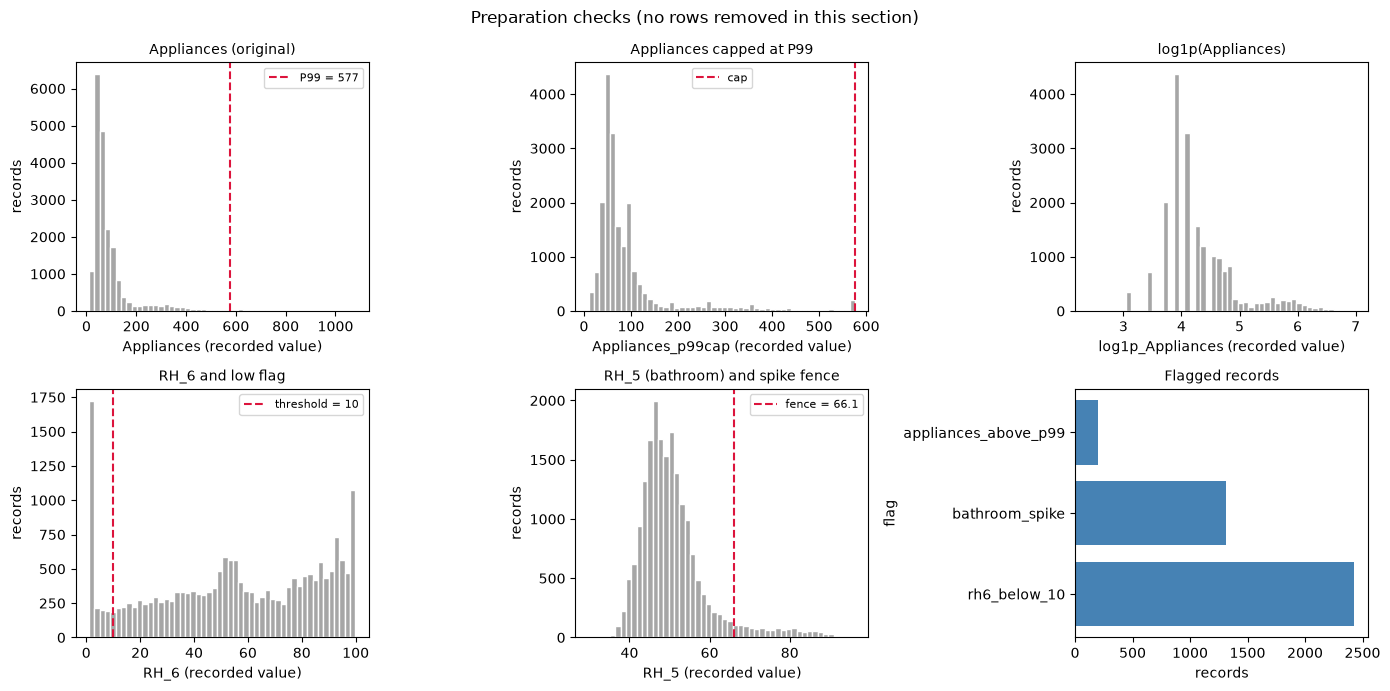

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7)); ax = ax.ravel()
panels = [(TARGET, "Appliances (original)", P99, f"P99 = {P99:.0f}"), (CAP, "Appliances capped at P99", P99, "cap"),
          (LOG1P, "log1p(Appliances)", None, None), ("RH_6", "RH_6 and low flag", RH6_LOW, f"threshold = {RH6_LOW:g}"),
          ("RH_5", "RH_5 (bathroom) and spike fence", FENCE, f"fence = {FENCE:.1f}")]
for a, (c, t, v, lab) in zip(ax, panels):
    a.hist(df[c].dropna(), bins=50, color="0.65", edgecolor="white")
    if v is not None: a.axvline(v, color="crimson", ls="--", label=lab); a.legend(fontsize=8)
    a.set_title(t, fontsize=10); a.set_xlabel(f"{c} (recorded value)"); a.set_ylabel("records")
ax[5].barh([f[5:] for f in FLAGS], df[FLAGS].sum(), color="steelblue")
ax[5].set_title("Flagged records", fontsize=10); ax[5].set_xlabel("records"); ax[5].set_ylabel("flag")
fig.suptitle("Preparation checks (no rows removed in this section)"); plt.tight_layout(); plt.show()

**Interpretation:** The plot compares the original, capped and log-transformed target and shows where each flag threshold sits.

## 3 · Build the ABT

Add calendar and diagnostic columns, define feature groups, resolve nulls, validate and save. Targets, flags, `rv1` and random columns stay out of the predictor list by construction.

### Method: Temporal Feature Extraction

- **Reference:** Candanedo, L. M., Feldheim, V., & Deramaix, D. (2017). Data driven prediction models of energy use of appliances in a low-energy house. *Energy and Buildings, 140*, 81–97. https://doi.org/10.1016/j.enbuild.2017.01.083
- **Documentation:** https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.hour.html
- **Purpose in this project:** `hour` (0–23) and `dayofweek` (0 = Monday) as plain integers capture occupancy routines. Encoding is left to the modeling pipeline.

In [10]:
# --- calendar features ---
df["hour"] = df["date"].dt.hour.astype("int8")
df["dayofweek"] = df["date"].dt.dayofweek.astype("int8")

### Method: Random-Column Null (Negative-Control) Features

- **Reference:** Stoppiglia, H., Dreyfus, G., Dubois, R., & Oussar, Y. (2003). Ranking a random feature for variable and feature selection. *Journal of Machine Learning Research, 3*, 1399–1414. https://www.jmlr.org/papers/v3/stoppiglia03a.html
- **Documentation:** https://numpy.org/doc/stable/reference/random/generator.html
- **Purpose in this project:** 20 seeded N(0,1) columns give a null reference: a real feature group should beat what pure noise achieves. They are **not predictors**.

In [11]:
# --- random diagnostic columns ---
RANDOM = [f"random_{i:02d}" for i in range(1, N_RANDOM + 1)]
df[RANDOM] = np.random.default_rng(SEED).standard_normal((len(df), N_RANDOM))

### Method: Feature-Group Manifest

- **Reference:** Wilson, G., Aruliah, D. A., Brown, C. T., Chue Hong, N. P., Davis, M., Guy, R. T., et al. (2014). Best practices for scientific computing. *PLoS Biology, 12*(1), e1001745. https://doi.org/10.1371/journal.pbio.1001745
- **Documentation:** https://docs.python.org/3/library/json.html
- **Purpose in this project:** defines groups once in `feature_groups.json` so later notebooks never redefine them ("don't repeat yourself"). Every column belongs to exactly one core group.

In [12]:
# --- feature groups ---
PHYSICAL = [c for c in ORIGINAL_COLS if c not in ("date", TARGET, "rv1")]
CAL = ["hour", "dayofweek"]
groups = {"identifiers_time": ["date"], "target_original": [TARGET], "target_derivatives": [CAP, LOG1P, LOG1P_CAP],
          "diagnostic_flags": FLAGS, "calendar_features": CAL, "physical_measurements": PHYSICAL,
          "negative_control_rv1": ["rv1"], "random_diagnostic": RANDOM}

indoor = [f"T{i}" for i in (1, 2, 3, 4, 5, 7, 8, 9)] + [f"RH_{i}" for i in (1, 2, 3, 4, 5, 7, 8, 9)]
outdoor = ["T6", "RH_6", "T_out", "RH_out", "Press_mm_hg", "Windspeed", "Visibility", "Tdewpoint"]
analysis_groups = {"temporal": CAL, "indoor": indoor, "outdoor": outdoor, "indoor_outdoor": indoor + outdoor,
                   "temporal_indoor_outdoor": CAL + indoor + outdoor,
                   "negative_control_rv1": ["rv1"], "negative_control_random": RANDOM}
assigned = sum(groups.values(), [])
check("groups cover every column once", sorted(assigned) == sorted(df.columns), "a column is unassigned or duplicated")
check("analysis groups use real columns", set(sum(analysis_groups.values(), [])) <= set(df.columns))

manifest = {"groups": groups, "predictor_candidates": PHYSICAL + CAL, "analysis_groups": analysis_groups,
            "notes": "targets, flags, rv1 and random columns are never predictors; hour/dayofweek are integers to encode in the modeling pipeline"}
(OUT / "feature_groups.json").write_text(json.dumps(manifest, indent=2))
print({k: len(v) for k, v in groups.items()})

{'identifiers_time': 1, 'target_original': 1, 'target_derivatives': 3, 'diagnostic_flags': 3, 'calendar_features': 2, 'physical_measurements': 24, 'negative_control_rv1': 1, 'random_diagnostic': 20}


**Interpretation:** The group sizes confirm every column is assigned once, with 24 physical measurements, 2 calendar integers and 20 random diagnostics kept apart from targets and flags.

### Method: Missing-Target Exclusion and Time-Based Interpolation

- **Reference:** Little, R. J. A., & Rubin, D. B. (2019). *Statistical analysis with missing data* (3rd ed.). Wiley. https://doi.org/10.1002/9781119482260
- **Documentation:** https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.interpolate.html
- **Purpose in this project:** rows with missing `Appliances` are excluded (labels are never imputed). Missing inputs are time-interpolated up to 1 hour, then forward/back filled, all counted. Interpolation uses both neighbours, so if you split by time later, impute inside training blocks.

In [13]:
# --- exclude missing target, repair missing inputs ---
abt = df.loc[df[TARGET].notna()].copy()
N_EXCLUDED = N_READ - len(abt)
inputs = PHYSICAL + ["rv1"]
n_missing_inputs = int(abt[inputs].isna().sum().sum())
if n_missing_inputs:
    abt[inputs] = abt.set_index("date")[inputs].interpolate("time", limit=INTERP_LIMIT, limit_direction="both").ffill().bfill().to_numpy()
log("3", "exclude missing target", f"{N_EXCLUDED} rows")
log("3", "repair missing inputs", f"{n_missing_inputs} cells (time interpolation, limit {INTERP_LIMIT}; ffill/bfill fallback)")

### Method: Assertion-Based Integrity Checks

- **Reference:** Wilson, G., Aruliah, D. A., Brown, C. T., Chue Hong, N. P., Davis, M., Guy, R. T., et al. (2014). Best practices for scientific computing. *PLoS Biology, 12*(1), e1001745. https://doi.org/10.1371/journal.pbio.1001745
- **Documentation:** https://docs.python.org/3/reference/simple_stmts.html#the-assert-statement
- **Purpose in this project:** five checks run before the freeze: unique ordered timestamps, target unchanged, 20 random columns, cap and `log1p` consistent, zero nulls. A failed check stops the run.

In [14]:
# --- integrity checks ---
below = abt[TARGET] <= P99
check("timestamps unique and ordered", abt["date"].is_unique and abt["date"].is_monotonic_increasing, "fix duplicate or unordered timestamps in the source")
check("original target unchanged", np.array_equal(abt[TARGET].to_numpy(), TARGET_ORIG.loc[abt.index].to_numpy()))
check("20 random columns", len(RANDOM) == N_RANDOM and sum(c.startswith("random_") for c in abt.columns) == N_RANDOM)
check("cap and log1p consistent", (abt.loc[below, CAP] == abt.loc[below, TARGET]).all() and (abt[CAP] <= P99).all()
      and np.allclose(abt[LOG1P], np.log1p(abt[TARGET])) and np.allclose(abt[LOG1P_CAP], np.log1p(abt[CAP])))
check("ABT has zero nulls", abt.isna().sum().sum() == 0, "nulls remain; they cannot be filled without fabricating values")

order = sum([groups[k] for k in ("identifiers_time", "target_original", "target_derivatives", "diagnostic_flags",
                                 "calendar_features", "physical_measurements", "negative_control_rv1", "random_diagnostic")], [])
abt = abt[order].reset_index(drop=True)
print(f"Rows excluded (missing {TARGET}): {N_EXCLUDED} | missing input cells repaired: {n_missing_inputs}")
print(f"Per-column null check: all {abt.shape[1]} columns have 0 nulls | ABT: {abt.shape[0]:,} rows x {abt.shape[1]} columns")

Rows excluded (missing Appliances): 0 | missing input cells repaired: 0
Per-column null check: all 55 columns have 0 nulls | ABT: 19,735 rows x 55 columns


**Interpretation:** The ABT passed every integrity check and has zero nulls, so it is safe to freeze.

### Method: Reproducible Freeze of the ABT

- **Reference:** Sandve, G. K., Nekrutenko, A., Taylor, J., & Hovig, E. (2013). Ten simple rules for reproducible computational research. *PLoS Computational Biology, 9*(10), e1003285. https://doi.org/10.1371/journal.pcbi.1003285
- **Documentation:** https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html
- **Purpose in this project:** saves the ABT, feature groups, metadata (seed, thresholds, counts) and cleaning log, so every downstream number traces to a file.

In [15]:
FILES = [OUT / n for n in ("abt_appliances_energy.csv", "feature_groups.json", "abt_metadata.json", "cleaning_log.csv")]
abt.assign(date=abt["date"].dt.strftime("%Y-%m-%d %H:%M:%S")).to_csv(FILES[0], index=False)

meta = {"input_file": path.name, "run_timestamp": datetime.now().isoformat(timespec="seconds"), "random_seed": SEED,
        "rows": abt.shape[0], "columns": abt.shape[1], "rows_read": N_READ, "rows_excluded_missing_target": N_EXCLUDED,
        "date_start": str(abt.date.min()), "date_end": str(abt.date.max()),
        "targets": {"original": TARGET, "capped": CAP, "log1p": LOG1P, "log1p_capped": LOG1P_CAP},
        "thresholds": {"rh6_low": RH6_LOW, "bathroom_fence": FENCE, "tukey_k": TUKEY_K, "cap_quantile": CAP_Q, "cap_value": P99, "interp_limit": INTERP_LIMIT},
        "feature_group_names": list(groups), "dropped_columns": ["rv2", "lights"]}
FILES[2].write_text(json.dumps(meta, indent=2))
pd.DataFrame(LOG).to_csv(FILES[3], index=False)
for f in FILES: print("saved:", f)

display(pd.DataFrame(LOG))

saved: abt_outputs\abt_appliances_energy.csv
saved: abt_outputs\feature_groups.json
saved: abt_outputs\abt_metadata.json
saved: abt_outputs\cleaning_log.csv


,step,action,detail
0,1,hidden-missing scan,text->NaN: 0; inf->NaN: 0
1,2,"drop rv2, lights",rv2 identical to rv1 (rv1 kept); lights is ano...
2,2,flags,RH_6<10.0; RH_5>66.058 (Q3+1.5*IQR); Appliance...
3,3,exclude missing target,0 rows
4,3,repair missing inputs,"0 cells (time interpolation, limit 6; ffill/bf..."


## 4 · Descriptive Statistics & Observations

Summaries of the finished ABT, grouped by role. Targets, flags, `rv1` and random columns are **not** predictors and are shown separately.

### Method: Descriptive Statistics Summary (with Skewness and Kurtosis)

- **Reference:** Joanes, D. N., & Gill, C. A. (1998). Comparing measures of sample skewness and kurtosis. *Journal of the Royal Statistical Society: Series D (The Statistician), 47*(1), 183–189. https://doi.org/10.1111/1467-9884.00122
- **Documentation:** https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html
- **Purpose in this project:** mean, SD, quantiles, skewness and excess kurtosis show center, spread and shape; skew and kurtosis expose asymmetry and heavy tails.

In [16]:
def describe(cols):
    d = abt[cols].describe(percentiles=[.05, .25, .5, .75, .95]).T.rename(columns={"50%": "median"})
    d["skew"], d["excess_kurtosis"] = abt[cols].skew(), abt[cols].kurt()
    d["raw_missing_pct"] = RAW_MISSING_PCT.reindex(d.index)
    return d[["raw_missing_pct", "mean", "std", "min", "5%", "25%", "median", "75%", "95%", "max", "skew", "excess_kurtosis"]]

print("A. Physical measurements (original; candidate predictors)"); display(describe(PHYSICAL))

print("B. Target and derivatives (TARGETS, not predictors)"); display(describe([TARGET, CAP, LOG1P, LOG1P_CAP]))

rd = describe(RANDOM)
print(f"C. Diagnostics (not predictors): rv1 mean {abt.rv1.mean():.2f}, SD {abt.rv1.std():.2f} | random columns pooled: "
      f"mean in [{rd['mean'].min():.3f}, {rd['mean'].max():.3f}], SD in [{rd['std'].min():.3f}, {rd['std'].max():.3f}]")

A. Physical measurements (original; candidate predictors)


,raw_missing_pct,mean,std,min,5%,25%,median,75%,95%,max,skew,excess_kurtosis
T1,0.000,21.687,1.606,16.790,19.100,20.760,21.600,22.600,24.726,26.260,0.121,0.162
RH_1,0.000,40.260,3.979,27.023,34.700,37.333,39.657,43.067,47.327,63.360,0.466,0.113
T2,0.000,20.341,2.193,16.100,17.323,18.790,20.000,21.500,24.558,29.857,0.890,0.933
RH_2,0.000,40.420,4.070,20.463,33.432,37.900,40.500,43.260,46.664,56.027,-0.268,0.671
T3,0.000,22.268,2.006,17.200,19.500,20.790,22.100,23.290,26.200,29.236,0.451,-0.007
RH_3,0.000,39.243,3.255,28.767,34.760,36.900,38.530,41.760,45.090,50.163,0.468,-0.583
T4,0.000,20.855,2.043,15.100,17.790,19.530,20.667,22.100,24.500,26.200,0.170,-0.038
RH_4,0.000,39.027,4.341,27.660,33.000,35.530,38.400,42.157,46.790,51.090,0.445,-0.614
T5,0.000,19.592,1.845,15.330,17.100,18.277,19.390,20.620,23.390,25.795,0.558,0.113
RH_5,0.000,50.949,9.022,29.815,40.790,45.400,49.090,53.663,70.390,96.322,1.867,4.503


B. Target and derivatives (TARGETS, not predictors)


,raw_missing_pct,mean,std,min,5%,25%,median,75%,95%,max,skew,excess_kurtosis
Appliances,0.000,97.695,102.525,10.000,30.000,50.000,60.000,100.000,330.000,"1,080.000",3.386,13.668
Appliances_p99cap,NaN,96.694,96.829,10.000,30.000,50.000,60.000,100.000,330.000,576.600,2.968,9.245
log1p_Appliances,NaN,4.320,0.649,2.398,3.434,3.932,4.111,4.615,5.802,6.986,1.190,1.588
log1p_Appliances_p99cap,NaN,4.318,0.644,2.398,3.434,3.932,4.111,4.615,5.802,6.359,1.146,1.384


C. Diagnostics (not predictors): rv1 mean 24.99, SD 14.50 | random columns pooled: mean in [-0.019, 0.015], SD in [0.991, 1.012]


**Interpretation:** Useful for spotting outliers or scaling issues before modeling; the random columns should sit near mean 0 and SD 1.

In [17]:
qs = [.5, .75, .9, .95, .99]
ladder = pd.DataFrame({f"{TARGET} (uncapped)": [abt[TARGET].quantile(q) for q in qs] + [abt[TARGET].max()],
                       CAP: [abt[CAP].quantile(q) for q in qs] + [abt[CAP].max()]}, index=[f"P{int(q*100)}" for q in qs] + ["max"])
print("\nEnergy percentile ladder"); display(ladder)

flag_tbl = pd.DataFrame({"records": abt[FLAGS].sum(), "pct_of_abt": abt[FLAGS].mean() * 100})
ANY_FLAG = int(abt[FLAGS].any(axis=1).sum())
print("Diagnostic flags"); display(flag_tbl)
print(f"KEY NUMBERS: read {N_READ:,} | excluded {N_EXCLUDED} | ABT {abt.shape[0]:,} x {abt.shape[1]} | any flag {ANY_FLAG:,}")


Energy percentile ladder


,Appliances (uncapped),Appliances_p99cap
P50,60.000,60.000
P75,100.000,100.000
P90,196.000,196.000
P95,330.000,330.000
P99,576.600,574.356
max,"1,080.000",576.600


Diagnostic flags


,records,pct_of_abt
flag_rh6_below_10,2428,12.303
flag_bathroom_spike,1314,6.658
flag_appliances_above_p99,198,1.003


KEY NUMBERS: read 19,735 | excluded 0 | ABT 19,735 x 55 | any flag 3,685


**Interpretation:** Capping at P99 changes only the top of the distribution; every lower percentile is identical. Each flag is sized before any sensitivity run uses it.

### Notable findings

Auto-generated from this run's data only. Add your own interpretation after them.

In [18]:
t, tc = abt[TARGET], abt[CAP]
shape = "right-skewed" if t.skew() > 0.5 else "left-skewed" if t.skew() < -0.5 else "roughly symmetric"
lines = [
 f"- **Rows.** {N_READ:,} read, {N_EXCLUDED} excluded for missing `{TARGET}`; ABT is {abt.shape[0]:,} x {abt.shape[1]}.",
 f"- **Cadence and nulls.** {n_exact:,} of {len(gaps):,} intervals are exactly 10 min ({n_gap} gaps); {int(nulls.missing.sum())} missing cells; {n_converted + int(inf_mask.sum())} hidden-missing conversions.",
 f"- **Target shape.** `{TARGET}` is {shape} (skew {t.skew():.2f}; mean {t.mean():.1f} vs median {t.median():.1f}); skew after `log1p` is {abt[LOG1P].skew():.2f}.",
 f"- **Cap effect.** P{int(CAP_Q*100)} = {P99:.1f} changes {int((t > P99).sum())} records; the mean moves {(tc.mean() / t.mean() - 1) * 100:+.2f}% and the max goes from {t.max():.0f} to {tc.max():.0f}.",
 *[f"- **`{f}`.** {int(abt[f].sum()):,} records ({abt[f].mean() * 100:.2f}%)." for f in FLAGS],
 f"- **Any flag.** {ANY_FLAG:,} records ({ANY_FLAG / len(abt) * 100:.2f}%); all kept. RH_6 minimum is {abt.RH_6.min():.2f}; whether low values are sensor faults is not decided here."]
display(Markdown("\n".join(lines)))

- **Rows.** 19,735 read, 0 excluded for missing `Appliances`; ABT is 19,735 x 55.
- **Cadence and nulls.** 19,734 of 19,734 intervals are exactly 10 min (0 gaps); 0 missing cells; 0 hidden-missing conversions.
- **Target shape.** `Appliances` is right-skewed (skew 3.39; mean 97.7 vs median 60.0); skew after `log1p` is 1.19.
- **Cap effect.** P99 = 576.6 changes 198 records; the mean moves -1.03% and the max goes from 1080 to 577.
- **`flag_rh6_below_10`.** 2,428 records (12.30%).
- **`flag_bathroom_spike`.** 1,314 records (6.66%).
- **`flag_appliances_above_p99`.** 198 records (1.00%).
- **Any flag.** 3,685 records (18.67%); all kept. RH_6 minimum is 1.00; whether low values are sensor faults is not decided here.

## 5 · Run Summary

Reloads the saved ABT, confirms all files exist, reports runtime and final shape, and prints success only if every check passed.

In [19]:
back = pd.read_csv(FILES[0])
check("saved ABT reloads with same shape and columns", back.shape == abt.shape and list(back.columns) == list(abt.columns))
check("all output files exist", all(f.is_file() for f in FILES))

print(f"Total runtime: {time.perf_counter() - T0:.1f} s")
print(f"ABT shape: {abt.shape[0]:,} rows x {abt.shape[1]} columns")
print("Files written:", *[str(f) for f in FILES], sep="\n  ")
assert all(CHECKS.values()), [k for k, v in CHECKS.items() if not v]
print(f"\n{len(CHECKS)} checks passed: " + "; ".join(CHECKS))
print("ALL CHECKS PASSED")

Total runtime: 3.5 s
ABT shape: 19,735 rows x 55 columns
Files written:
  abt_outputs\abt_appliances_energy.csv
  abt_outputs\feature_groups.json
  abt_outputs\abt_metadata.json
  abt_outputs\cleaning_log.csv

12 checks passed: required columns; rv1 == rv2; target non-negative; groups cover every column once; analysis groups use real columns; timestamps unique and ordered; original target unchanged; 20 random columns; cap and log1p consistent; ABT has zero nulls; saved ABT reloads with same shape and columns; all output files exist
ALL CHECKS PASSED


---
### Handoff to Notebook 2

| Question | What this ABT provides |
|---|---|
| **Q1 – Typical ranges** | Unscaled physical measurements and `Appliances` / `Appliances_p99cap` as targets |
| **Q2 – Thresholds** | `log1p_Appliances` target, anomaly flags for sensitivity runs, indoor/outdoor groups in `analysis_groups` |
| **Q3 – Variance explained** | `temporal`, `indoor`, `outdoor`, combined groups, plus `rv1` and 20 random columns as the null reference |

- Load: `abt = pd.read_csv("abt_outputs/abt_appliances_energy.csv", parse_dates=["date"])` and `manifest = json.load(open("abt_outputs/feature_groups.json"))`.
- Predictors come from `manifest["predictor_candidates"]` or `manifest["analysis_groups"]`, never from targets, flags, `rv1` or random columns.
- Targets: `Appliances`, `Appliances_p99cap`, `log1p_Appliances`, `log1p_Appliances_p99cap`. For sensitivity runs, filter on a flag or use the capped target; if rows are dropped, use timestamps (not row positions) to decide which records are consecutive.
- This is not a modeling split: build time-blocked partitions later and fit scalers and encoders on training blocks only.

### References

Box, G. E. P., & Cox, D. R. (1964). An analysis of transformations. *Journal of the Royal Statistical Society: Series B, 26*(2), 211–252. https://doi.org/10.1111/j.2517-6161.1964.tb00553.x

Candanedo, L. M., Feldheim, V., & Deramaix, D. (2017). Data driven prediction models of energy use of appliances in a low-energy house. *Energy and Buildings, 140*, 81–97. https://doi.org/10.1016/j.enbuild.2017.01.083

Joanes, D. N., & Gill, C. A. (1998). Comparing measures of sample skewness and kurtosis. *Journal of the Royal Statistical Society: Series D (The Statistician), 47*(1), 183–189. https://doi.org/10.1111/1467-9884.00122

Little, R. J. A., & Rubin, D. B. (2019). *Statistical analysis with missing data* (3rd ed.). Wiley. https://doi.org/10.1002/9781119482260

McKinney, W. (2010). Data structures for statistical computing in Python. In S. van der Walt & J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 56–61). https://doi.org/10.25080/Majora-92bf1922-00a

Sandve, G. K., Nekrutenko, A., Taylor, J., & Hovig, E. (2013). Ten simple rules for reproducible computational research. *PLoS Computational Biology, 9*(10), e1003285. https://doi.org/10.1371/journal.pcbi.1003285

Stoppiglia, H., Dreyfus, G., Dubois, R., & Oussar, Y. (2003). Ranking a random feature for variable and feature selection. *Journal of Machine Learning Research, 3*, 1399–1414. https://www.jmlr.org/papers/v3/stoppiglia03a.html

Tukey, J. W. (1962). The future of data analysis. *The Annals of Mathematical Statistics, 33*(1), 1–67. https://doi.org/10.1214/aoms/1177704711

Tukey, J. W. (1977). *Exploratory data analysis*. Addison-Wesley.

Wilson, G., Aruliah, D. A., Brown, C. T., Chue Hong, N. P., Davis, M., Guy, R. T., et al. (2014). Best practices for scientific computing. *PLoS Biology, 12*(1), e1001745. https://doi.org/10.1371/journal.pbio.1001745

Zhou, Y., Tu, F., Sha, K., Ding, J., & Chen, H. (2024). A survey on data quality dimensions and tools for machine learning. *arXiv*:2406.19614 (accepted at IEEE AITest 2024). https://doi.org/10.48550/arXiv.2406.19614